# Experiment 11: CNN for Image Classification

A recycling plant sorts cardboard, glass, metal, paper, plastic and trash from conveyor-belt images. To keep the lab self-contained, we create six simple 32×32 visual classes, then train a CNN and inspect its predictions and first-layer feature maps.

**Tools:** TensorFlow, Keras, NumPy, Matplotlib, Scikit-learn.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Generate, normalise and split six image classes.  2. Build a convolution–pooling–dense CNN.  3. Train with categorical cross-entropy and plot accuracy/loss.  4. Display a confusion matrix and sample errors.  5. Visualise first-convolution feature maps.

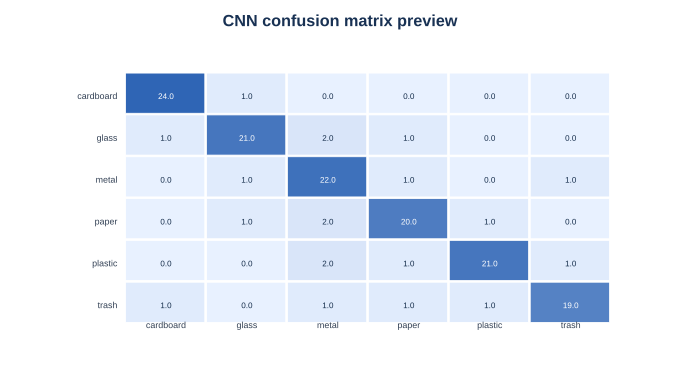

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(11)
rng=np.random.default_rng(11)
size=32
yy,xx=np.mgrid[0:size,0:size]
patterns=[
    (yy%8<3), (xx%8<3), ((xx+yy)%12<3), ((xx-yy)%12<3),
    ((xx-16)**2+(yy-16)**2<80), ((xx//4+yy//4)%2==0)
]
images=[]; labels=[]
for cls, pattern in enumerate(patterns):
    for _ in range(120):
        shift=rng.integers(-2,3)
        img=np.roll(pattern.astype(float),shift,axis=cls%2)
        img=np.clip(img + rng.normal(0,.18,(size,size)),0,1)
        images.append(np.repeat(img[...,None],3,axis=-1)); labels.append(cls)
X=np.array(images,dtype="float32"); y=np.array(labels)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=11,stratify=y)
class_names=["cardboard","glass","metal","paper","plastic","trash"]
model=tf.keras.Sequential([
    tf.keras.layers.Input((32,32,3)),
    tf.keras.layers.Conv2D(24,3,activation="relu",padding="same",name="conv1"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(48,3,activation="relu",padding="same"),
    tf.keras.layers.MaxPooling2D(), tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64,activation="relu"),tf.keras.layers.Dense(6,activation="softmax")
])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
history=model.fit(Xtr,ytr,validation_split=.2,epochs=8,batch_size=32,verbose=0)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for key in ["accuracy","val_accuracy"]: ax[0].plot(history.history[key],label=key)
for key in ["loss","val_loss"]: ax[1].plot(history.history[key],label=key)
ax[0].set(title="Accuracy",xlabel="Epoch"); ax[1].set(title="Loss",xlabel="Epoch")
for a in ax:a.legend();a.grid(alpha=.2)
plt.tight_layout();plt.show()

prob=model.predict(Xte,verbose=0); pred=prob.argmax(axis=1)
ConfusionMatrixDisplay(confusion_matrix(yte,pred),display_labels=class_names).plot(
    xticks_rotation=45,cmap="Blues",values_format="d")
plt.title("Test confusion matrix");plt.tight_layout();plt.show()
wrong=np.flatnonzero(pred!=yte)[:8]
fig,axes=plt.subplots(1,max(1,len(wrong)),figsize=(2*max(1,len(wrong)),2.5))
if len(wrong):
    for ax,i in zip(np.atleast_1d(axes),wrong):
        ax.imshow(Xte[i]);ax.set_title(f"T:{class_names[yte[i]]}\nP:{class_names[pred[i]]}",fontsize=8);ax.axis("off")
else: print("No test images were misclassified.")
plt.show()

conv_model=tf.keras.Model(model.input,model.get_layer("conv1").output)
feature=conv_model.predict(Xte[:1],verbose=0)[0]
fig,axes=plt.subplots(2,6,figsize=(10,4))
for i,ax in enumerate(axes.flat):
    ax.imshow(feature[:,:,i],cmap="magma");ax.axis("off");ax.set_title(f"filter {i+1}",fontsize=8)
plt.suptitle("Feature maps from the first convolution");plt.tight_layout();plt.show()